# Метрики качества ML-моделей — команда 403 (Sansara)

| Параметр | Значение |
|---|---|
| Дисциплина | Управление ИТ-продуктами |
| Занятие | 10. Метрики качества ML-моделей (методическая разработка `mguide-2-10`) |
| Продукт команды | **Sansara** — B2B-платформа, сопоставляющая складские остатки одних компаний с закупочными потребностями других |
| Команда | 403, группа 15.27Д-ИСТ04/25б |
| Преподаватель | Мамонов Вадим Григорьевич |
| Репозиторий | https://github.com/richal-su/sansara |

| Участник | Роль в проекте |
|---|---|
| Лебединцев Кирилл Иванович | Product Owner, координатор |
| Щипунов Дмитрий Владимирович | Product Analyst / UX |
| Мустафин Денис Димьянович | Business Analyst |
| Карпов Максим Сергеевич | Tech / Data Analyst |

Распределение работы и вклад участников — в разделе 7.

## Цель работы

Рассчитать ключевые метрики качества для трёх типов ML-задач (классификация, регрессия, рекомендации), построить графики и сделать продуктовые выводы: что означает результат для пользователя, какая метрика главная, какое ограничение нужно соблюдать, что проверить дальше и можно ли говорить о запуске.

**Структура ноутбука**

1. Конфигурация и источники данных
2. Проверка качества CSV
3. Классификация — метрики, матрица ошибок, ROC и PR, сравнение порогов 0,3 / 0,5 / 0,8
4. Регрессия — метрики и 3 графика, направление и размер ошибок
5. Рекомендации — метрики при k = 10, кривые по k, ручной пример, вывод о порядке выдачи
6. Общий итог и связь с Sansara
7. Команда, вклад и взаимная проверка
8. Приложение А — все варианты архива; воспроизводимость

> Все числа в выводах получены ячейками этого ноутбука на исходных CSV. Ячейки с проверками (`assert`) останавливают выполнение, если расчёт и ручная сверка расходятся.

In [1]:
# === Конфигурация работы: единственное место, где задаются варианты ===
TEAM = 403

# Номера вариантов датасетов. Предварительное соответствие: команда 403 → строка «3»
# таблицы распределения (слайд 5 презентации). Подтверждение — см. раздел 1.
VARIANTS = {
    "classification": 3,   # 3 — Спам в чате поддержки
    "regression": 8,       # 8 — LTV пользователя
    "recsys": 9,           # 9 — Рекомендации товаров
}
VARIANTS_CONFIRMED = False  # поставить True после подтверждения преподавателем

K = 10                          # глубина выдачи для рекомендаций (единая для всех команд)
THRESHOLDS = [0.3, 0.5, 0.8]    # пороги для сравнения в классификации
BASE_THRESHOLD = 0.5
REGRESSION_UNITS = "ед. данных"  # единицы LTV в данных не указаны

## 1. Источники данных и номера вариантов

**Источник.** Архив `metrics_datasets.zip` из репозитория курса [`amalrik/it-product-management`](https://gitverse.ru/amalrik/it-product-management) (каталог `resources/`), на который ссылается [методическое пособие к занятию 10](https://gitverse.ru/amalrik/it-product-management/content/master/practice/mguide-2-10.md). Все 10 CSV перенесены в `data/raw/seminar_10/` без изменений; контрольные суммы SHA-256 записаны в `data/raw/seminar_10/SHA256SUMS` и проверяются ниже при каждом запуске.

**Вариант.** Таблица распределения (слайд 5 презентации) задаёт командам 1–10 разные варианты для трёх задач. Код нашей команды **403** мы интерпретируем как «группа ИСТ04, команда № 3», поэтому используем строку **3**:

| Тип задачи | Вариант | Кейс | Файл |
|---|---|---|---|
| Классификация | 3 | Спам в чате службы поддержки | `variant_3_classification.csv` |
| Регрессия | 8 | LTV пользователя | `variant_8_regression.csv` |
| Рекомендации | 9 | Рекомендации товаров в интернет-магазине | `variant_9_recsys.csv` |

⚠️ **Соответствие «403 → строка 3» — допущение команды, документально не подтверждено** (в презентации и пособии нумерация команд 1–10). Поэтому:

- варианты задаются одной переменной `VARIANTS` в ячейке конфигурации выше, флаг `VARIANTS_CONFIRMED = False`;
- в **приложении А** теми же функциями посчитаны все 10 вариантов — если преподаватель укажет другую строку таблицы, достаточно поменять `VARIANTS` и перезапустить ноутбук.

Подробные выводы в тексте ниже написаны для вариантов 3 / 8 / 9.

In [2]:
import hashlib
import platform
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score, log_loss,
    mean_absolute_error, mean_absolute_percentage_error, mean_squared_error,
    precision_recall_curve, precision_score, r2_score, recall_score, roc_auc_score,
    roc_curve,
)

pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10})
# Предупреждения не подавляются: если какое-то вычисление некорректно, оно будет видно.

CASE_NAMES = {
    1: "Отток клиентов подписочного сервиса", 2: "Мошенничество (фрод) в платежах",
    3: "Спам в чате службы поддержки", 4: "Клик по рекламному баннеру (CTR)",
    5: "Одобрение кредитной заявки", 6: "Время доставки заказа",
    7: "Месячная выручка филиала", 8: "LTV (жизненная ценность) пользователя",
    9: "Рекомендации товаров в интернет-магазине",
    10: "Рекомендации плейлистов в музыкальном сервисе",
}
TASK_OF_VARIANT = {**{v: "classification" for v in range(1, 6)},
                   **{v: "regression" for v in range(6, 9)},
                   **{v: "recsys" for v in range(9, 11)}}
for task, v in VARIANTS.items():
    if TASK_OF_VARIANT.get(v) != task:
        raise ValueError(f"Вариант {v} не относится к типу задачи «{task}»")


def find_data_dir(rel="data/raw/seminar_10"):
    """Ищет каталог с CSV относительно текущей папки и её родителей (без абсолютных путей)."""
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        cand = base / rel
        if cand.is_dir():
            return cand
    raise FileNotFoundError(
        f"Не найден каталог {rel}. Запустите ноутбук из репозитория sansara "
        "и поместите в него CSV из архива metrics_datasets.zip.")


DATA_DIR = find_data_dir()
FILES = {
    "classification": DATA_DIR / f"variant_{VARIANTS['classification']}_classification.csv",
    "regression": DATA_DIR / f"variant_{VARIANTS['regression']}_regression.csv",
    "recsys": DATA_DIR / f"variant_{VARIANTS['recsys']}_recsys.csv",
}


def verify_checksums(data_dir):
    """Сверяет SHA-256 файлов с контрольными суммами, снятыми с архива преподавателя."""
    sums_file = data_dir / "SHA256SUMS"
    if not sums_file.exists():
        print("SHA256SUMS не найден — проверка целостности пропущена.")
        return
    bad = []
    for line in sums_file.read_text().splitlines():
        digest, name = line.split()
        path = data_dir / name
        if not path.exists() or hashlib.sha256(path.read_bytes()).hexdigest() != digest:
            bad.append(name)
    if bad:
        raise ValueError(f"Файлы не совпадают с исходным архивом: {bad}")
    print(f"Целостность подтверждена: {len(sums_file.read_text().splitlines())} CSV "
          "побайтно совпадают с архивом metrics_datasets.zip.")


verify_checksums(DATA_DIR)
print("Каталог данных:", DATA_DIR.relative_to(DATA_DIR.parents[2]))
print("Статус вариантов:", "подтверждены" if VARIANTS_CONFIRMED else
      "ПРЕДВАРИТЕЛЬНЫЕ (нужно подтверждение преподавателя)")
pd.DataFrame([{"Тип задачи": t, "Вариант": v, "Кейс": CASE_NAMES[v], "Файл": FILES[t].name}
              for t, v in VARIANTS.items()])

Целостность подтверждена: 10 CSV побайтно совпадают с архивом metrics_datasets.zip.
Каталог данных: data/raw/seminar_10
Статус вариантов: ПРЕДВАРИТЕЛЬНЫЕ (нужно подтверждение преподавателя)


,Тип задачи,Вариант,Кейс,Файл
0,classification,3,Спам в чате службы поддержки,variant_3_classification.csv
1,regression,8,LTV (жизненная ценность) пользователя,variant_8_regression.csv
2,recsys,9,Рекомендации товаров в интернет-магазине,variant_9_recsys.csv


## 2. Проверка качества исходных CSV

Для каждого файла проверяем размер, состав и типы столбцов, пропуски и дубликаты строк. Специфические проверки (доля класса, нули, длины списков) — в начале каждого раздела.

In [3]:
REQUIRED_COLUMNS = {
    "classification": ["y_true", "y_pred", "y_score"],
    "regression": ["y_true", "y_pred"],
    "recsys": ["user_id", "recommended_items", "relevant_items"],
}


def load_csv(task):
    path = FILES[task]
    if not path.exists():
        raise FileNotFoundError(f"Нет файла {path.name} в {DATA_DIR}")
    df = pd.read_csv(path, dtype=str if task == "recsys" else None)
    missing = set(REQUIRED_COLUMNS[task]) - set(df.columns)
    if missing:
        raise ValueError(f"{path.name}: нет обязательных столбцов {missing}")
    return df


raw = {task: load_csv(task) for task in FILES}

overview = pd.DataFrame([{
    "Файл": FILES[t].name,
    "Строк": len(df),
    "Столбцы": ", ".join(df.columns),
    "Типы": ", ".join(str(x) for x in df.dtypes),
    "Пропусков": int(df.isna().sum().sum()),
    "Дубликатов строк": int(df.duplicated().sum()),
} for t, df in raw.items()])
overview

,Файл,Строк,Столбцы,Типы,Пропусков,Дубликатов строк
0,variant_3_classification.csv,350,"y_true, y_pred, y_score","int64, int64, float64",0,71
1,variant_8_regression.csv,350,"y_true, y_pred","float64, float64",0,0
2,variant_9_recsys.csv,120,"user_id, recommended_items, relevant_items","str, str, str",0,0


## 3. Классификация — вариант 3 «Спам в чате службы поддержки»

**Кейс.** Модель отличает спам от нормальных обращений клиентов. Положительный класс `1` — спам.

| Ошибка | Что происходит в продукте |
|---|---|
| **FP** (норма → спам) | Обычное обращение клиента скрыто или ограничено: клиент не получает помощь, растёт негатив и отток |
| **FN** (спам → норма) | Спам доходит до оператора: тратится время поддержки, растёт очередь |

**Допущение о `y_score`.** Считаем `y_score` оценкой вероятности класса «спам»: значения лежат в [0; 1], а исходный `y_pred` в точности равен `y_score ≥ 0,5` (проверено ниже). На этом допущении считается LogLoss. Калиброванность вероятностей данными не подтверждена.

### 3.1. Проверка данных

In [4]:
CLASS_LABELS = {1: ("уход", "остаётся"), 2: ("фрод", "норма"), 3: ("спам", "норма"),
                4: ("клик", "нет клика"), 5: ("одобрить", "отказать")}
POS, NEG = CLASS_LABELS[VARIANTS["classification"]]   # подписи классов 1 и 0 для графиков

cls = raw["classification"].copy()
y_true = cls["y_true"].to_numpy()
y_pred = cls["y_pred"].to_numpy()
y_score = cls["y_score"].to_numpy(dtype=float)

assert set(np.unique(y_true)) <= {0, 1}, "y_true должен быть бинарным"
assert set(np.unique(y_pred)) <= {0, 1}, "y_pred должен быть бинарным"
assert np.all((y_score >= 0) & (y_score <= 1)), "y_score вне [0, 1]"

pred_at_05 = (y_score >= BASE_THRESHOLD).astype(int)
conf_err_pos = int(((y_score == 0) & (y_true == 1)).sum())
conf_err_neg = int(((y_score == 1) & (y_true == 0)).sum())
cls_checks = pd.Series({
    "Записей": len(cls),
    "Значения y_true": sorted(np.unique(y_true).tolist()),
    f"Доля класса 1 ({POS}), %": round(100 * y_true.mean(), 1),
    "Объектов класса 1": int(y_true.sum()),
    "Диапазон y_score": f"[{y_score.min():.3f}; {y_score.max():.3f}]",
    "y_score ровно 0 / ровно 1": f"{int((y_score == 0).sum())} / {int((y_score == 1).sum())}",
    "y_pred совпадает с (y_score ≥ 0,5), %": round(100 * (y_pred == pred_at_05).mean(), 1),
    "Расхождений y_pred и порога 0,5": int((y_pred != pred_at_05).sum()),
    "Уверенных ошибок (score=0 при y=1 / score=1 при y=0)": f"{conf_err_pos} / {conf_err_neg}",
}, name="Значение")
cls_checks.to_frame()

,Значение
Записей,350
Значения y_true,"[0, 1]"
"Доля класса 1 (спам), %",37.1
Объектов класса 1,130
Диапазон y_score,[0.000; 1.000]
y_score ровно 0 / ровно 1,27 / 15
"y_pred совпадает с (y_score ≥ 0,5), %",100.0
"Расхождений y_pred и порога 0,5",0
Уверенных ошибок (score=0 при y=1 / score=1 при y=0),0 / 0


**Что показала проверка.**

- 350 сообщений, спама 130 (**37,1%**) — умеренный дисбаланс. Модель «всё не спам» уже даёт Accuracy 0,629, поэтому Accuracy нужно сравнивать с этим уровнем, а не с нулём.
- `y_pred` на 100% совпадает с правилом `y_score ≥ 0,5`: исходные предсказания получены порогом 0,5.
- 27 значений `y_score` равны ровно 0 и 15 — ровно 1. Похоже, что оценки обрезаны до [0; 1], поэтому это не обязательно калиброванные вероятности. «Уверенных ошибок» (score = 0 у спама или 1 у нормы) нет, поэтому LogLoss конечен.
- 71 полностью совпадающая строка в обзоре — это не ошибка выгрузки: при трёх знаках у `y_score` разные сообщения дают одинаковые тройки значений. Строки не удаляем.

### 3.2. Метрики исходного `y_pred`

In [5]:
def confusion_counts(yt, yp):
    """TP, TN, FP, FN, посчитанные явно (без sklearn) — для сверки."""
    yt, yp = np.asarray(yt), np.asarray(yp)
    return {"TP": int(((yt == 1) & (yp == 1)).sum()), "TN": int(((yt == 0) & (yp == 0)).sum()),
            "FP": int(((yt == 0) & (yp == 1)).sum()), "FN": int(((yt == 1) & (yp == 0)).sum())}


def classification_metrics(yt, yp, ys=None):
    """Метрики по жёстким решениям yp; если передан ys — ещё и ранжирующие метрики."""
    c = confusion_counts(yt, yp)
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    assert (tp, tn, fp, fn) == (c["TP"], c["TN"], c["FP"], c["FN"]), "TP/TN/FP/FN не сходятся"
    m = {"Accuracy": accuracy_score(yt, yp),
         "Precision": precision_score(yt, yp, zero_division=0),
         "Recall": recall_score(yt, yp, zero_division=0),
         "F1": f1_score(yt, yp, zero_division=0)}
    # ручная сверка формул
    assert np.isclose(m["Precision"], tp / (tp + fp) if tp + fp else 0)
    assert np.isclose(m["Recall"], tp / (tp + fn) if tp + fn else 0)
    if ys is not None:
        m["ROC AUC"] = roc_auc_score(yt, ys)
        m["AP (average_precision_score)"] = average_precision_score(yt, ys)
        # LogLoss: предполагаем, что y_score — вероятность класса 1 (см. текст).
        m["LogLoss"] = log_loss(yt, ys, labels=[0, 1])
    return m, c


cls_metrics, cls_counts = classification_metrics(y_true, y_pred, y_score)
prevalence = y_true.mean()
print("Матрица ошибок исходного y_pred:", cls_counts)
const_logloss = log_loss(y_true, np.full(len(y_true), prevalence), labels=[0, 1])
print(f"Базовые уровни: доля класса 1 = {prevalence:.3f} (это AP случайной модели); "
      f"Accuracy модели «всё — класс 0» = {1 - prevalence:.3f}; "
      f"LogLoss постоянного прогноза доли класса 1 = {const_logloss:.3f}")
pd.Series(cls_metrics, name=f"Вариант {VARIANTS['classification']}, исходный y_pred").to_frame().round(3)

Матрица ошибок исходного y_pred: {'TP': 101, 'TN': 168, 'FP': 52, 'FN': 29}
Базовые уровни: доля класса 1 = 0.371 (это AP случайной модели); Accuracy модели «всё — класс 0» = 0.629; LogLoss постоянного прогноза доли класса 1 = 0.660


,"Вариант 3, исходный y_pred"
Accuracy,0.769
Precision,0.660
Recall,0.777
F1,0.714
ROC AUC,0.855
AP (average_precision_score),0.787
LogLoss,0.478


**Интерпретация для поддержки (порог 0,5).**

- **Precision 0,660**: из 153 сообщений, отправленных в спам, 52 — обычные обращения клиентов. Ошибочна примерно каждая третья блокировка.
- **Recall 0,777**: модель поймала 101 из 130 спам-сообщений, 29 дошли до операторов.
- **Accuracy 0,769** лишь на 14 п. п. выше тривиального уровня 0,629 — по ней одной качество модели оценивать нельзя.
- **F1 0,714** — общий баланс точности и полноты при пороге 0,5.
- **ROC AUC 0,855**: в 85,5% случайных пар «спам — норма» спам получает более высокий score. Модель хорошо *ранжирует* сообщения, проблема в выборе порога.
- **AP 0,787** против 0,371 у случайной модели — заметный запас по качеству ранжирования спама. Значение получено `average_precision_score` и подписано именно как AP.
- **LogLoss 0,478** при допущении, что `y_score` — вероятность; постоянный прогноз доли спама даёт 0,660. Вероятности информативны, но их калибровку нужно проверить отдельно.

### 3.3. Графики: матрица ошибок, ROC и PR

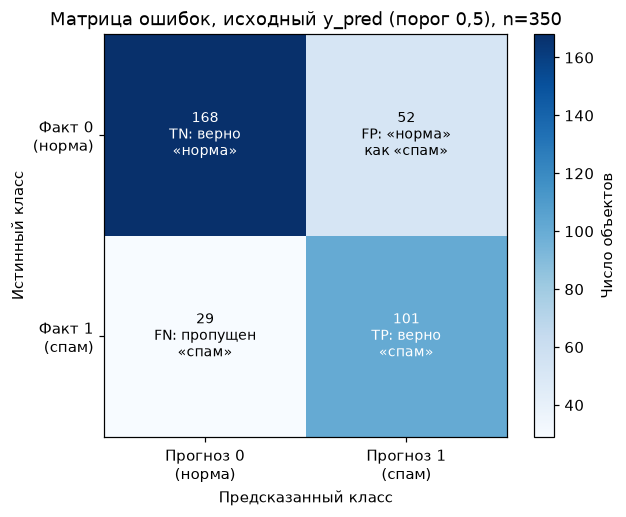

In [6]:
def plot_confusion(counts, title):
    mat = np.array([[counts["TN"], counts["FP"]], [counts["FN"], counts["TP"]]])
    fig, ax = plt.subplots(figsize=(6, 4.8))
    im = ax.imshow(mat, cmap="Blues")
    labels = [[f"TN: верно\n«{NEG}»", f"FP: «{NEG}»\nкак «{POS}»"],
              [f"FN: пропущен\n«{POS}»", f"TP: верно\n«{POS}»"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{mat[i, j]}\n{labels[i][j]}", ha="center", va="center",
                    color="white" if mat[i, j] > mat.max() / 2 else "black", fontsize=9)
    ax.set_xticks([0, 1], [f"Прогноз 0\n({NEG})", f"Прогноз 1\n({POS})"])
    ax.set_yticks([0, 1], [f"Факт 0\n({NEG})", f"Факт 1\n({POS})"])
    ax.set_xlabel("Предсказанный класс"); ax.set_ylabel("Истинный класс")
    ax.set_title(title); ax.grid(False)
    fig.colorbar(im, ax=ax, label="Число объектов")
    plt.tight_layout(); plt.show()


plot_confusion(cls_counts, f"Матрица ошибок, исходный y_pred (порог 0,5), n={len(cls)}")

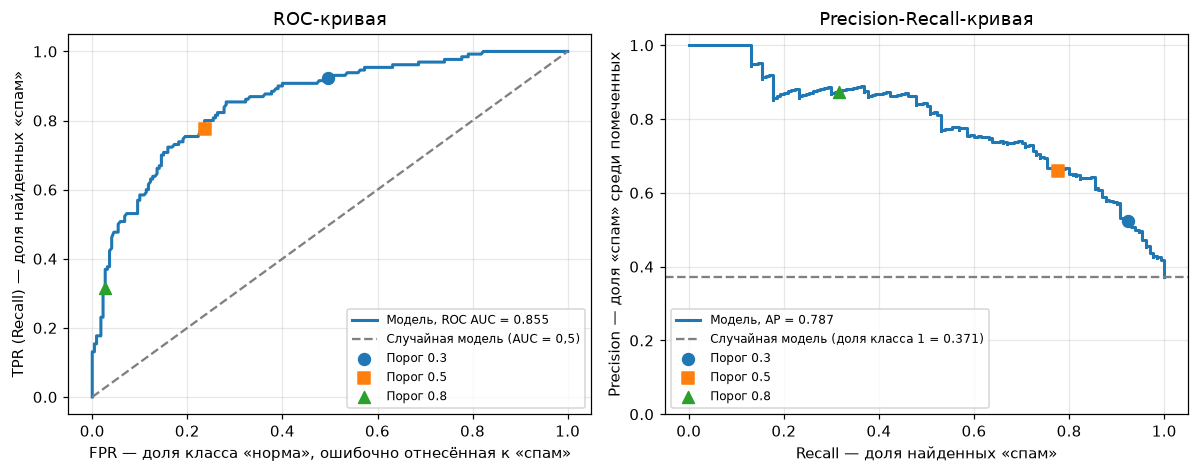

In [7]:
fpr, tpr, _ = roc_curve(y_true, y_score)
prec_curve, rec_curve, _ = precision_recall_curve(y_true, y_score)

thr_points = []
for t in THRESHOLDS:
    c = confusion_counts(y_true, (y_score >= t).astype(int))
    thr_points.append({"t": t, "fpr": c["FP"] / (c["FP"] + c["TN"]), "tpr": c["TP"] / (c["TP"] + c["FN"]),
                       "precision": c["TP"] / (c["TP"] + c["FP"]) if c["TP"] + c["FP"] else np.nan})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.plot(fpr, tpr, lw=2, label=f"Модель, ROC AUC = {cls_metrics['ROC AUC']:.3f}")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Случайная модель (AUC = 0,5)")
for p, mk in zip(thr_points, ["o", "s", "^"]):
    ax.scatter(p["fpr"], p["tpr"], s=60, marker=mk, zorder=3, label=f"Порог {p['t']}")
ax.set_xlabel(f"FPR — доля класса «{NEG}», ошибочно отнесённая к «{POS}»")
ax.set_ylabel(f"TPR (Recall) — доля найденных «{POS}»")
ax.set_title("ROC-кривая"); ax.legend(loc="lower right", fontsize=8)

ax = axes[1]
ax.plot(rec_curve, prec_curve, lw=2, drawstyle="steps-post",
        label=f"Модель, AP = {cls_metrics['AP (average_precision_score)']:.3f}")
ax.axhline(prevalence, ls="--", color="grey", label=f"Случайная модель (доля класса 1 = {prevalence:.3f})")
for p, mk in zip(thr_points, ["o", "s", "^"]):
    ax.scatter(p["tpr"], p["precision"], s=60, marker=mk, zorder=3, label=f"Порог {p['t']}")
ax.set_xlabel(f"Recall — доля найденных «{POS}»")
ax.set_ylabel(f"Precision — доля «{POS}» среди помеченных")
ax.set_title("Precision-Recall-кривая"); ax.set_ylim(0, 1.03); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**Что видно на кривых.** Отмеченные точки — пороги 0,3 / 0,5 / 0,8, координаты посчитаны по тем же данным, что и таблица ниже.

- На ROC-кривой переход от порога 0,5 к 0,8 снижает долю ошибочно скрытых нормальных сообщений с 23,6% до 2,7%, но полнота падает с 0,777 до 0,315.
- На PR-кривой самые уверенные предсказания (первые 13% спама) идут без единой ошибки. На участке recall 0,2–0,45 precision держится на уровне 0,86–0,89, затем снижается до 0,66 на пороге 0,5.
- Ни одна точка не даёт одновременно высокую точность и высокую полноту, поэтому выбор порога — продуктовое решение о цене ошибок.

### 3.4. Сравнение порогов 0,3 / 0,5 / 0,8

Новые решения строятся как `y_pred_t = (y_score ≥ t)`. Исходный `y_pred` сохранён выше; строка `t = 0,5` его воспроизводит (проверено `assert`).

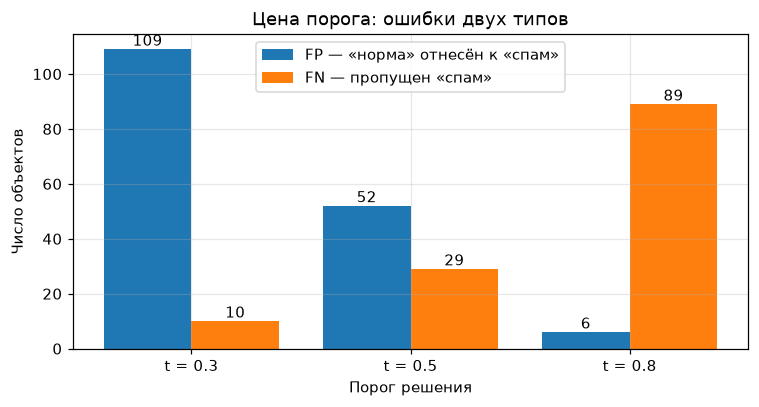

,Положительных решений,TP,FP,FN,"FPR, %",Precision,Recall,F1
Порог t,,,,,,,,
0.3,229,120,109,10,49.545,0.524,0.923,0.669
0.5,153,101,52,29,23.636,0.660,0.777,0.714
0.8,47,41,6,89,2.727,0.872,0.315,0.463


In [8]:
def threshold_table(yt, ys, thresholds):
    rows = []
    for t in thresholds:
        yp_t = (ys >= t).astype(int)           # y_pred_t = (y_score ≥ t)
        m, c = classification_metrics(yt, yp_t)
        rows.append({"Порог t": t, "Положительных решений": int(yp_t.sum()),
                     "TP": c["TP"], "FP": c["FP"], "FN": c["FN"],
                     "FPR, %": 100 * c["FP"] / (c["FP"] + c["TN"]),
                     "Precision": m["Precision"], "Recall": m["Recall"], "F1": m["F1"]})
    return pd.DataFrame(rows).set_index("Порог t")


thr_table = threshold_table(y_true, y_score, THRESHOLDS)
# контроль: если исходный y_pred получен порогом 0,5, строка t = 0,5 должна его воспроизводить
if (y_pred == pred_at_05).all():
    assert thr_table.loc[0.5, "FP"] == cls_counts["FP"] and thr_table.loc[0.5, "FN"] == cls_counts["FN"]
else:
    print(f"Внимание: исходный y_pred отличается от (y_score ≥ 0,5) в {int((y_pred != pred_at_05).sum())} строках")

fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(THRESHOLDS))
b1 = ax.bar(x - 0.2, thr_table["FP"], 0.4, label=f"FP — «{NEG}» отнесён к «{POS}»")
b2 = ax.bar(x + 0.2, thr_table["FN"], 0.4, label=f"FN — пропущен «{POS}»")
ax.bar_label(b1); ax.bar_label(b2)
ax.set_xticks(x, [f"t = {t}" for t in THRESHOLDS])
ax.set_xlabel("Порог решения"); ax.set_ylabel("Число объектов")
ax.set_title("Цена порога: ошибки двух типов"); ax.legend()
plt.tight_layout(); plt.show()
thr_table.round(3)

**Как порог меняет ошибки.**

| Порог | В спам | FP (норма скрыта) | FN (спам пропущен) | Precision | Recall |
|---|---:|---:|---:|---:|---:|
| 0,3 | 229 | 109 (49,5% нормы) | 10 | 0,524 | 0,923 |
| 0,5 | 153 | 52 (23,6% нормы) | 29 | 0,660 | 0,777 |
| 0,8 | 47 | 6 (2,7% нормы) | 89 | 0,872 | 0,315 |

- **0,3** ловит 92% спама, но скрывает почти половину нормальных обращений. Для поддержки это неприемлемо.
- **0,5** скрывает каждое четвёртое нормальное обращение — для автоматической блокировки тоже слишком много.
- **0,8** почти не трогает клиентов (6 ошибок из 220), но пропускает 69% спама.

### Продуктовый вывод — классификация

1. **Результат.** Модель хорошо ранжирует сообщения (ROC AUC 0,855, AP 0,787), но при пороге 0,5 скрывает 52 нормальных обращения из 220. Для клиента это ситуация «написал в поддержку — ответа нет».
2. **Основная метрика — Precision класса «спам»** (эквивалентно — доля ошибочно скрытых обращений, FPR), если действие продукта — скрыть сообщение. Ошибка FP бьёт по клиенту, FN — только по времени оператора.
3. **Ограничение — Recall не ниже согласованного минимума**, иначе фильтр не разгружает операторов. Требования поддержки (допустимая доля скрытых обращений, стоимость минуты оператора) нам не даны.
4. **Следующий шаг.** Использовать модель в двухпороговом режиме: высокий score (≈ 0,8) — карантин с возможностью восстановить сообщение, средний — пометка и понижение приоритета для оператора, низкий — обычная очередь. Пороги подбирать на **независимой** отложенной выборке и проверить калибровку `y_score`. Порог, выбранный на этих 350 строках, окончательным считать нельзя.
5. **Границы вывода.** Для автоматической блокировки модель в текущем виде требует доработки; как инструмент сортировки очереди с ручной проверкой — пригодна с оговорками. **Данных для решения о запуске недостаточно**: нет требований к допустимым ошибкам и проверки на независимых данных.

## 4. Регрессия — вариант 8 «LTV пользователя»

**Кейс.** Модель оценивает суммарный доход от пользователя за период. LTV используют, чтобы ограничить стоимость привлечения (CAC) и выбрать сегменты для удержания.

**Единицы.** В данных и пособии единицы LTV не указаны, поэтому везде пишем «ед. данных».

**Остаток** = `y_true − y_pred`. Положительный остаток означает **недооценку** LTV, отрицательный — переоценку.

### 4.1. Проверка данных

In [9]:
reg = raw["regression"].copy()
yt_r = reg["y_true"].to_numpy(dtype=float)
yp_r = reg["y_pred"].to_numpy(dtype=float)
residuals = yt_r - yp_r          # остаток > 0 — модель НЕДООЦЕНИЛА LTV

q1, q3 = np.percentile(yt_r, [25, 75])
iqr_hi = q3 + 1.5 * (q3 - q1)
reg_checks = pd.Series({
    "Записей": len(reg),
    "Пропусков": int(reg.isna().sum().sum()),
    f"y_true: мин / медиана / макс, {REGRESSION_UNITS}": f"{yt_r.min():.2f} / {np.median(yt_r):.2f} / {yt_r.max():.2f}",
    f"y_pred: мин / медиана / макс, {REGRESSION_UNITS}": f"{yp_r.min():.2f} / {np.median(yp_r):.2f} / {yp_r.max():.2f}",
    "Нулей в y_true": int((yt_r == 0).sum()),
    "Отрицательных y_true / y_pred": f"{int((yt_r < 0).sum())} / {int((yp_r < 0).sum())}",
    "Прогнозов ровно 0": int((yp_r == 0).sum()),
    "y_true < 10 (малые значения)": int((yt_r < 10).sum()),
    f"Выбросов y_true по правилу 1,5·IQR (> {iqr_hi:.1f})": int((yt_r > iqr_hi).sum()),
}, name="Значение")
reg_checks.to_frame()

,Значение
Записей,350
Пропусков,0
"y_true: мин / медиана / макс, ед. данных",4.53 / 96.38 / 398.83
"y_pred: мин / медиана / макс, ед. данных",0.00 / 99.88 / 420.51
Нулей в y_true,0
Отрицательных y_true / y_pred,0 / 0
Прогнозов ровно 0,9
y_true < 10 (малые значения),3
"Выбросов y_true по правилу 1,5·IQR (> 312.5)",9


**Что показала проверка.**

- 350 пользователей, пропусков нет; LTV от 4,53 до 398,83 ед. данных, медиана 96,38.
- Нулей и отрицательных значений в `y_true` нет, поэтому MAPE формально определена. Но 3 значения меньше 10, и относительная ошибка на них может быть очень большой — ниже проверяем чувствительность MAPE.
- **9 прогнозов ровно 0** — вероятно, отрицательные прогнозы модели обрезаны до нуля. Фактический LTV у этих пользователей от 4,5 до 52,5 ед.: модель «списывает» платящих пользователей.
- 9 значений выше 312,5 по правилу 1,5·IQR — естественный длинный хвост LTV (ценные клиенты), а не ошибки. Данные не удаляем и не меняем.

### 4.2. Метрики

In [10]:
def regression_metrics(yt, yp):
    if np.any(yt == 0):
        # MAPE не определена при y_true = 0: не заменяем нули, а явно сообщаем.
        warnings.warn("В y_true есть нули — MAPE не определена, см. WAPE")
        mape = np.nan
    else:
        mape = mean_absolute_percentage_error(yt, yp)
    mse = mean_squared_error(yt, yp)
    return {"MAE": mean_absolute_error(yt, yp), "MSE": mse, "RMSE": np.sqrt(mse),
            "R²": r2_score(yt, yp), "MAPE, %": 100 * mape,
            # дополнительные устойчивые показатели (не заменяют обязательные)
            "Медиана |ошибки|": np.median(np.abs(yt - yp)),
            "WAPE, % (Σ|ошибка| / Σ факт)": 100 * np.abs(yt - yp).sum() / np.abs(yt).sum(),
            "Средний остаток (смещение)": np.mean(yt - yp)}


reg_metrics = regression_metrics(yt_r, yp_r)
ape = np.abs(residuals) / yt_r
mape_sensitivity = pd.Series({
    "MAPE по всем объектам, %": 100 * ape.mean(),
    "Медианная APE, %": 100 * np.median(ape),
    "MAPE без 10% наименьших y_true, %": 100 * ape[yt_r >= np.percentile(yt_r, 10)].mean(),
    "MAPE без прогнозов, равных 0, %": 100 * ape[yp_r != 0].mean(),
    "Объектов с APE > 100%": int((ape > 1).sum()),
}, name="Чувствительность MAPE")
display(pd.Series(reg_metrics, name=f"Вариант {VARIANTS['regression']}, {REGRESSION_UNITS}").to_frame().round(3))
mape_sensitivity.to_frame().round(2)

,"Вариант 8, ед. данных"
MAE,20.069
MSE,645.739
RMSE,25.411
R²,0.888
"MAPE, %",26.377
Медиана |ошибки|,15.725
"WAPE, % (Σ|ошибка| / Σ факт)",17.185
Средний остаток (смещение),-0.470


,Чувствительность MAPE
"MAPE по всем объектам, %",26.38
"Медианная APE, %",16.15
"MAPE без 10% наименьших y_true, %",21.62
"MAPE без прогнозов, равных 0, %",24.43
Объектов с APE > 100%,4.00


**Интерпретация.**

- **MAE 20,07 ед.** — в среднем прогноз LTV ошибается на 20 ед. при медианном LTV 96 (около 21% медианы). Это главная «бизнесовая» цифра: насколько можно ошибиться в бюджете на одного пользователя.
- **RMSE 25,41** лишь в 1,27 раза больше MAE (для нормально распределённых ошибок отношение ≈ 1,25), то есть редких катастрофических промахов немного. **MSE 645,74** — квадрат ошибки; для интерпретации удобнее RMSE.
- **R² 0,888**: модель объясняет 89% разброса LTV и намного лучше прогноза «всем средний LTV». Это не означает точности 89% для каждого пользователя.
- **MAPE 26,4%** завышена малыми значениями: медианная относительная ошибка 16,2%, WAPE 17,2%, без 10% самых маленьких LTV MAPE = 21,6%. Четыре пользователя имеют относительную ошибку больше 100%. MAPE оставляем справочной метрикой, нули не заменяем.
- **Среднее смещение −0,47** почти нулевое — но, как показывают графики, оно скрывает систематические ошибки в разных сегментах.

### 4.3. Графики ошибок

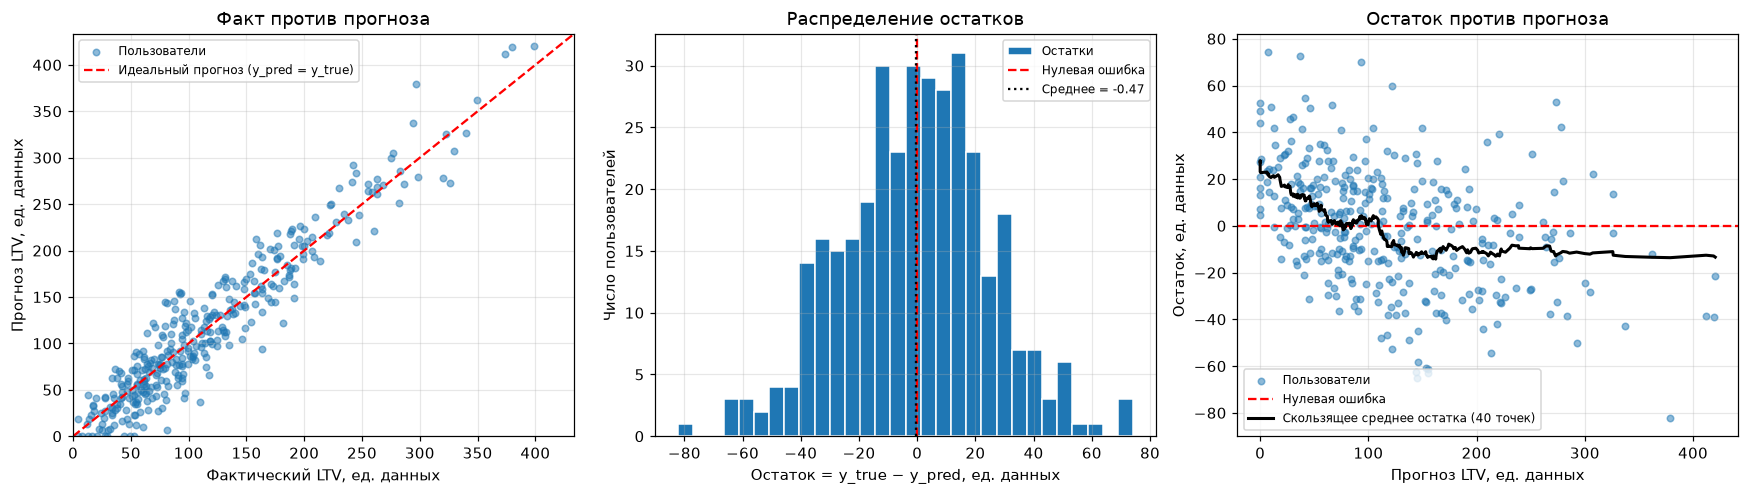

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
lims = [0, max(yt_r.max(), yp_r.max()) * 1.03]

ax = axes[0]
ax.scatter(yt_r, yp_r, alpha=0.5, s=18, label="Пользователи")
ax.plot(lims, lims, "--", color="red", label="Идеальный прогноз (y_pred = y_true)")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel(f"Фактический LTV, {REGRESSION_UNITS}"); ax.set_ylabel(f"Прогноз LTV, {REGRESSION_UNITS}")
ax.set_title("Факт против прогноза"); ax.legend(loc="upper left", fontsize=8)

ax = axes[1]
ax.hist(residuals, bins=30, edgecolor="white", label="Остатки")
ax.axvline(0, color="red", ls="--", label="Нулевая ошибка")
ax.axvline(residuals.mean(), color="black", ls=":", label=f"Среднее = {residuals.mean():.2f}")
ax.set_xlabel(f"Остаток = y_true − y_pred, {REGRESSION_UNITS}"); ax.set_ylabel("Число пользователей")
ax.set_title("Распределение остатков"); ax.legend(fontsize=8)

ax = axes[2]
ax.scatter(yp_r, residuals, alpha=0.5, s=18, label="Пользователи")
ax.axhline(0, color="red", ls="--", label="Нулевая ошибка")
order = np.argsort(yp_r)
roll = pd.Series(residuals[order]).rolling(40, center=True, min_periods=20).mean()
ax.plot(yp_r[order], roll, color="black", lw=2, label="Скользящее среднее остатка (40 точек)")
ax.set_xlabel(f"Прогноз LTV, {REGRESSION_UNITS}"); ax.set_ylabel(f"Остаток, {REGRESSION_UNITS}")
ax.set_title("Остаток против прогноза"); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

In [12]:
quart = pd.qcut(yp_r, 4, labels=["Q1 (низкий прогноз)", "Q2", "Q3", "Q4 (высокий прогноз)"])
by_q = pd.DataFrame({"Остаток": residuals, "|Остаток|": np.abs(residuals), "Прогноз": yp_r,
                     "Факт": yt_r}).groupby(quart, observed=True).agg(
    Пользователей=("Остаток", "size"), Средний_прогноз=("Прогноз", "mean"),
    Средний_факт=("Факт", "mean"), Средний_остаток=("Остаток", "mean"), MAE=("|Остаток|", "mean"))
display(by_q.round(2))

big_thr = 2 * reg_metrics["RMSE"]
big = reg.assign(остаток=residuals, abs_ошибка=np.abs(residuals)).sort_values("abs_ошибка", ascending=False)
print(f"Крупные ошибки (|остаток| > 2·RMSE = {big_thr:.1f}): {int((np.abs(residuals) > big_thr).sum())} "
      f"из {len(reg)}; недооценок {int((residuals > big_thr).sum())}, переоценок {int((residuals < -big_thr).sum())}")
print("Корреляция |остатка| с прогнозом:", round(np.corrcoef(yp_r, np.abs(residuals))[0, 1], 3))
big.head(8).round(2)

,Пользователей,Средний_прогноз,Средний_факт,Средний_остаток,MAE
Q1 (низкий прогноз),88,30.02,45.97,15.95,20.14
Q2,87,77.06,78.75,1.69,16.40
Q3,87,129.61,121.40,-8.20,21.99
Q4 (высокий прогноз),88,232.01,220.63,-11.38,21.73


Крупные ошибки (|остаток| > 2·RMSE = 50.8): 17 из 350; недооценок 8, переоценок 9
Корреляция |остатка| с прогнозом: 0.112


,y_true,y_pred,остаток,abs_ошибка
102,296.71,378.90,-82.19,82.19
281,81.34,7.17,74.17,74.17
159,109.95,37.23,72.72,72.72
325,163.61,93.61,70.00,70.00
249,79.80,144.87,-65.07,65.07
235,91.87,154.95,-63.08,63.08
266,81.11,143.82,-62.71,62.71
92,93.74,154.78,-61.04,61.04


**Анализ ошибок.**

- **Направление.** В среднем модель не смещена (−0,47), но смещение зависит от уровня прогноза. В нижней четверти прогнозов LTV **недооценён** в среднем на 15,95 ед. (прогноз 30,0 против факта 46,0 — примерно на треть ниже). В верхней четверти LTV **переоценён** на 11,38 ед. Прогнозы «растянуты» сильнее факта — это видно по скользящему среднему на третьем графике.
- **Размер типичной ошибки.** Медиана |остатка| 15,7 ед., MAE по четвертям от 16,4 до 22,0 ед. Абсолютная ошибка почти не растёт с прогнозом (корреляция |остатка| с прогнозом 0,11), поэтому для маленьких клиентов *относительная* ошибка заметно больше.
- **Крупные ошибки.** 17 пользователей (4,9%) с |остатком| > 2·RMSE = 50,8 ед.; недооценок 8, переоценок 9. Максимальная — переоценка на 82 ед. (факт 296,7, прогноз 378,9).
- **Проблемы данных.** 9 нулевых прогнозов у реально платящих пользователей и неизвестные единицы измерения.

### Продуктовый вывод — регрессия

1. **Результат.** Модель хорошо упорядочивает пользователей по ценности (R² 0,888), но ошибается в среднем на 20 ед. на пользователя и систематически завышает LTV «дорогих» сегментов. Если по прогнозу ограничивать CAC, переоценка верхней четверти ведёт к переплате за привлечение похожих пользователей. Недооценка и нулевые прогнозы ведут к тому, что живых клиентов не включают в программы удержания.
2. **Основная метрика — MAE** в денежных единицах на пользователя: её прямо переводят в риск ошибки бюджета.
3. **Ограничение** — среднее смещение в каждом сегменте (децили или четверти прогноза) по модулю не больше согласованного допуска; доля нулевых прогнозов у платящих пользователей — 0. MAPE используем только справочно из-за малых значений.
4. **Следующий шаг.** Откалибровать края прогноза на отложенной выборке (например, линейная рекалибровка `y ≈ a + b·прогноз`). Заменить обрезку в 0 моделью для неотрицательной цели (логарифм LTV). Проверить качество на следующей когорте пользователей (разбиение по времени) и уточнить единицы.
5. **Границы вывода.** Для ранжирования и сегментации пользователей модель пригодна с оговорками; для расчёта бюджета на конкретного пользователя требует калибровки. **Данных для решения о запуске недостаточно**: не заданы единицы, допустимая ошибка и период LTV.

## 5. Рекомендации — вариант 9 «Рекомендации товаров в интернет-магазине»

**Кейс.** Модель формирует список из 10 товаров, которые стоит предложить пользователю. `relevant_items` — товары, которые оказались для пользователя релевантными (известная «правильная» часть).

### 5.1. Разбор и проверка данных

Списки разбираются по разделителю `;` **в исходном порядке**: порядок выдачи не сортируется и не меняется (проверено `assert` — склейка разобранного списка совпадает с исходной строкой). Идентификаторы читаются как строки, чтобы не потерять ведущие нули и не смешать типы.

In [13]:
def parse_items(s):
    """Строка 'a;b;c' → список в ИСХОДНОМ порядке. Пустая строка/NaN → пустой список."""
    if pd.isna(s) or str(s).strip() == "":
        return []
    return [x.strip() for x in str(s).split(";") if x.strip() != ""]


rec_df = raw["recsys"].copy()
rec_df["rec"] = rec_df["recommended_items"].apply(parse_items)
rec_df["rel"] = rec_df["relevant_items"].apply(parse_items)

# Проверка, что порядок не изменён при разборе
assert (rec_df["rec"].apply(";".join) == rec_df["recommended_items"].str.strip()).all()

rec_checks = pd.Series({
    "Пользователей (строк)": len(rec_df),
    "Уникальных user_id": rec_df["user_id"].nunique(),
    "Длина списка рекомендаций (мин–макс)": f"{rec_df['rec'].str.len().min()}–{rec_df['rec'].str.len().max()}",
    "Пустых списков рекомендаций": int((rec_df["rec"].str.len() == 0).sum()),
    "Пустой релевантности": int((rec_df["rel"].str.len() == 0).sum()),
    "Релевантных объектов на пользователя (мин–макс)": f"{rec_df['rel'].str.len().min()}–{rec_df['rel'].str.len().max()}",
    "Распределение числа релевантных": rec_df["rel"].str.len().value_counts().sort_index().to_dict(),
    "Пользователей с повторами в рекомендациях": int(rec_df["rec"].apply(lambda r: len(r) != len(set(r))).sum()),
    "Пользователей с повторами в релевантных": int(rec_df["rel"].apply(lambda r: len(r) != len(set(r))).sum()),
    "Пользователей, у кого релевантных > K": int((rec_df["rel"].str.len() > K).sum()),
    "Уникальных товаров в рекомендациях": len(set().union(*rec_df["rec"])),
}, name="Значение")
rec_checks.to_frame()

,Значение
Пользователей (строк),120
Уникальных user_id,120
Длина списка рекомендаций (мин–макс),10–10
Пустых списков рекомендаций,0
Пустой релевантности,0
Релевантных объектов на пользователя (мин–макс),1–3
Распределение числа релевантных,"{1: 47, 2: 39, 3: 34}"
Пользователей с повторами в рекомендациях,0
Пользователей с повторами в релевантных,0
"Пользователей, у кого релевантных > K",0


**Правила расчёта (методика слайда 13 + наши решения для граничных случаев).**

| Правило | Как реализовано |
|---|---|
| Основная глубина | `K = 10` для всех метрик |
| Precision@k | число попаданий в top-k **делим на k**, даже если список короче k (важно для варианта 10, где 5 объектов) |
| Recall@k | попадания в top-k / число известных релевантных |
| AP@k | сумма Precision@i в позициях попаданий / **min(число релевантных, k)** |
| RR, MRR | 1 / позиция первого попадания по **всему переданному списку**, без обрезки до k; 0 — если попаданий нет |
| NDCG@k | бинарная полезность 0/1, DCG = Σ 1/log₂(i+1); IDCG — идеальное размещение min(\|rel\|, k) попаданий |
| Усреднение | простое среднее по пользователям — у каждого одинаковый вес |
| Пустая релевантность | метрики не определены (NaN), пользователь **исключается** из средних и показывается отдельно. В варианте 9 таких пользователей 0, результат от правила не зависит |
| Повтор объекта в выдаче | засчитывается **один раз** (первое вхождение); повтор занимает позицию, но полезности не даёт. Повторов в варианте 9 нет |
| Повтор в релевантных | релевантные берутся как множество |

In [14]:
def _hits(rec, rel, k=None):
    """Флаги попаданий 0/1 по позициям top-k. Повтор объекта засчитывается один раз
    (первое вхождение), повтор занимает позицию, но не даёт полезности."""
    rel = set(rel)
    seen, flags = set(), []
    for item in (rec if k is None else rec[:k]):
        flags.append(1 if (item in rel and item not in seen) else 0)
        seen.add(item)
    return flags


def precision_at_k(rec, rel, k):
    return sum(_hits(rec, rel, k)) / k                 # делим на k, даже если список короче


def recall_at_k(rec, rel, k):
    return sum(_hits(rec, rel, k)) / len(set(rel)) if rel else np.nan


def ap_at_k(rec, rel, k):
    if not rel:
        return np.nan
    score, n_hit = 0.0, 0
    for i, h in enumerate(_hits(rec, rel, k), start=1):
        if h:
            n_hit += 1
            score += n_hit / i                          # Precision@i в позиции попадания
    return score / min(len(set(rel)), k)                # нормировка на min(|rel|, k)


def reciprocal_rank(rec, rel):
    if not rel:
        return np.nan
    for i, h in enumerate(_hits(rec, rel), start=1):    # по ВСЕМУ списку, без обрезки до k
        if h:
            return 1 / i
    return 0.0


def ndcg_at_k(rec, rel, k):
    if not rel:
        return np.nan
    dcg = sum(h / np.log2(i + 1) for i, h in enumerate(_hits(rec, rel, k), start=1))   # полезность 0/1
    idcg = sum(1 / np.log2(i + 1) for i in range(1, min(len(set(rel)), k) + 1))
    return dcg / idcg


def user_metrics(rec, rel, k=K):
    return {f"Precision@{k}": precision_at_k(rec, rel, k), f"Recall@{k}": recall_at_k(rec, rel, k),
            f"AP@{k}": ap_at_k(rec, rel, k), "RR": reciprocal_rank(rec, rel),
            f"NDCG@{k}": ndcg_at_k(rec, rel, k)}

### 5.2. Автоматические проверки функций на ручных примерах

Ожидаемые значения посчитаны вручную, например для теста 1: попадания на позициях 2 и 4, |rel| = 2 → AP@10 = (1/2 + 2/4) / 2 = 0,5; NDCG@10 = (1/log₂3 + 1/log₂5) / (1 + 1/log₂3) = 1,0616 / 1,6309 = 0,6509. Тесты покрывают короткий список, попадание за пределами top-10 (RR), число релевантных больше k, повторы и влияние порядка.

In [15]:
# Автотесты на примерах, посчитанных вручную (значения — из ручного расчёта, не из функций)
def check(name, got, expected, tol=1e-4):
    ok = (np.isnan(got) and np.isnan(expected)) or abs(got - expected) < tol
    assert ok, f"{name}: получено {got}, ожидалось {expected}"
    return {"Тест": name, "Ожидалось": expected, "Получено": round(got, 5), "OK": "✓"}


tests = []
# 1. Короткий список (5 объектов), попадания на позициях 2 и 4, |rel| = 2
r1, g1 = ["a", "b", "c", "d", "e"], ["b", "d"]
tests += [check("1. P@10 короткого списка = 2/10", precision_at_k(r1, g1, 10), 0.2),
          check("1. P@5 = 2/5", precision_at_k(r1, g1, 5), 0.4),
          check("1. Recall@10 = 2/2", recall_at_k(r1, g1, 10), 1.0),
          check("1. AP@10 = (1/2 + 2/4)/2", ap_at_k(r1, g1, 10), 0.5),
          check("1. RR = 1/2", reciprocal_rank(r1, g1), 0.5),
          check("1. NDCG@10 = (1/log2 3 + 1/log2 5)/(1 + 1/log2 3)", ndcg_at_k(r1, g1, 10), 0.650921)]
# 2. Единственное попадание на позиции 12: в top-10 его нет, но RR считается по всему списку
r2 = [f"x{i}" for i in range(1, 12)] + ["hit"]
tests += [check("2. P@10 = 0", precision_at_k(r2, ["hit"], 10), 0.0),
          check("2. AP@10 = 0", ap_at_k(r2, ["hit"], 10), 0.0),
          check("2. RR = 1/12 (по всему списку)", reciprocal_rank(r2, ["hit"]), 1 / 12)]
# 3. Релевантных 12 > k: все 10 позиций — попадания
r3 = [f"y{i}" for i in range(10)]
g3 = r3 + ["y10", "y11"]
tests += [check("3. AP@10 = 1 (нормировка на min(12, 10))", ap_at_k(r3, g3, 10), 1.0),
          check("3. Recall@10 = 10/12", recall_at_k(r3, g3, 10), 10 / 12),
          check("3. NDCG@10 = 1", ndcg_at_k(r3, g3, 10), 1.0)]
# 4. Повтор в выдаче засчитывается один раз
tests += [check("4. P@3 при повторе [x, x, y], rel={x} = 1/3", precision_at_k(["x", "x", "y"], ["x"], 3), 1 / 3),
          check("4. NDCG@3 при повторе = 1", ndcg_at_k(["x", "x", "y"], ["x"], 3), 1.0)]
# 5. Порядок важен: тот же набор, попадание первым или последним
tests += [check("5. AP@3 попадание на 1-й позиции", ap_at_k(["h", "n1", "n2"], ["h"], 3), 1.0),
          check("5. AP@3 попадание на 3-й позиции", ap_at_k(["n1", "n2", "h"], ["h"], 3), 1 / 3)]
print(f"Все {len(tests)} проверок пройдены.")
pd.DataFrame(tests)

Все 16 проверок пройдены.


,Тест,Ожидалось,Получено,OK
0,1. P@10 короткого списка = 2/10,0.2000,0.2000,✓
1,1. P@5 = 2/5,0.4000,0.4000,✓
2,1. Recall@10 = 2/2,1.0000,1.0000,✓
3,1. AP@10 = (1/2 + 2/4)/2,0.5000,0.5000,✓
4,1. RR = 1/2,0.5000,0.5000,✓
5,1. NDCG@10 = (1/log2 3 + 1/log2 5)/(1 + 1/log2 3),0.6509,0.6509,✓
6,2. P@10 = 0,0.0000,0.0000,✓
7,2. AP@10 = 0,0.0000,0.0000,✓
8,2. RR = 1/12 (по всему списку),0.0833,0.0833,✓
9,"3. AP@10 = 1 (нормировка на min(12, 10))",1.0000,1.0000,✓


In [16]:
per_user = pd.DataFrame([user_metrics(r, g, K) for r, g in zip(rec_df["rec"], rec_df["rel"])],
                        index=rec_df["user_id"])
per_user["Попаданий в top-10"] = [sum(_hits(r, g, K)) for r, g in zip(rec_df["rec"], rec_df["rel"])]
per_user["Позиция 1-го попадания"] = [next((i for i, h in enumerate(_hits(r, g), 1) if h), np.nan)
                                      for r, g in zip(rec_df["rec"], rec_df["rel"])]
excluded = per_user[f"Recall@{K}"].isna().sum()
valid = per_user.dropna(subset=[f"Recall@{K}"])     # пользователи с непустой релевантностью

rec_summary = pd.Series({
    f"Mean Precision@{K}": valid[f"Precision@{K}"].mean(),
    f"Mean Recall@{K}": valid[f"Recall@{K}"].mean(),
    f"MAP@{K}": valid[f"AP@{K}"].mean(),
    "MRR": valid["RR"].mean(),
    f"Mean NDCG@{K}": valid[f"NDCG@{K}"].mean(),
}, name=f"Вариант {VARIANTS['recsys']}, k = {K}")

n_users = len(valid)
n_hit_users = int((valid["Попаданий в top-10"] > 0).sum())
max_p10 = np.mean([min(len(set(g)), K) / K for g in rec_df["rel"]])   # потолок Precision@10
print(f"Пользователей в расчёте: {n_users} (исключено из-за пустой релевантности: {excluded})")
print(f"Хотя бы одно попадание в top-{K}: {n_hit_users} пользователей ({100 * n_hit_users / n_users:.1f}%)")
print(f"Без попаданий: {n_users - n_hit_users} пользователей ({100 * (1 - n_hit_users / n_users):.1f}%)")
print(f"Всего попаданий: {int(valid['Попаданий в top-10'].sum())} из {n_users * K} показанных позиций")
print(f"Теоретический максимум Mean Precision@{K} при идеальном ранжировании: {max_p10:.3f} "
      f"(у пользователей всего 1–3 релевантных объекта)")
rec_summary.to_frame().round(4)

Пользователей в расчёте: 120 (исключено из-за пустой релевантности: 0)
Хотя бы одно попадание в top-10: 18 пользователей (15.0%)
Без попаданий: 102 пользователей (85.0%)
Всего попаданий: 18 из 1200 показанных позиций
Теоретический максимум Mean Precision@10 при идеальном ранжировании: 0.189 (у пользователей всего 1–3 релевантных объекта)


,"Вариант 9, k = 10"
Mean Precision@10,0.0150
Mean Recall@10,0.0778
MAP@10,0.0214
MRR,0.0424
Mean NDCG@10,0.0411


In [17]:
# Пример ручного расчёта: первый пользователь, у которого есть попадание
ex_uid = valid.index[valid["Попаданий в top-10"] > 0][0]
ex = rec_df.set_index("user_id").loc[ex_uid]
flags = _hits(ex["rec"], ex["rel"], K)
pos = [i for i, h in enumerate(flags, 1) if h]
print(f"Пользователь {ex_uid}")
print("  Рекомендации (порядок сохранён):", ex["rec"])
print("  Релевантные:", ex["rel"], f"→ |rel| = {len(ex['rel'])}")
print("  Флаги попаданий по позициям:", flags, "→ позиции попаданий:", pos)
n_rel = len(set(ex["rel"]))
ap_terms = [(j + 1) / p for j, p in enumerate(pos)]          # Precision@i в позициях попаданий
dcg = sum(1 / np.log2(p + 1) for p in pos)
idcg = sum(1 / np.log2(i + 1) for i in range(1, min(n_rel, K) + 1))
print(f"  Precision@10 = {len(pos)}/10 = {len(pos) / 10:.3f}")
print(f"  Recall@10    = {len(pos)}/{n_rel} = {len(pos) / n_rel:.3f}")
print(f"  AP@10        = ({' + '.join(f'{j + 1}/{p}' for j, p in enumerate(pos))}) / min({n_rel}, 10) "
      f"= {sum(ap_terms) / min(n_rel, K):.4f}")
print(f"  RR           = 1/{pos[0]} = {1 / pos[0]:.4f}")
print(f"  NDCG@10      = DCG / IDCG = ({' + '.join(f'1/log2({p}+1)' for p in pos)}) / {idcg:.4f} "
      f"= {dcg / idcg:.4f}")
manual = {f"Precision@{K}": len(pos) / K, f"Recall@{K}": len(pos) / n_rel,
          f"AP@{K}": sum(ap_terms) / min(n_rel, K), "RR": 1 / pos[0], f"NDCG@{K}": dcg / idcg}
for key, val in manual.items():
    assert np.isclose(per_user.loc[ex_uid, key], val), key
print("  ✓ Ручной расчёт совпадает с функциями ноутбука.")

Пользователь 2
  Рекомендации (порядок сохранён): ['61', '93', '14', '44', '48', '25', '94', '45', '75', '68']
  Релевантные: ['72', '94'] → |rel| = 2
  Флаги попаданий по позициям: [0, 0, 0, 0, 0, 0, 1, 0, 0, 0] → позиции попаданий: [7]
  Precision@10 = 1/10 = 0.100
  Recall@10    = 1/2 = 0.500
  AP@10        = (1/7) / min(2, 10) = 0.0714
  RR           = 1/7 = 0.1429
  NDCG@10      = DCG / IDCG = (1/log2(7+1)) / 1.6309 = 0.2044
  ✓ Ручной расчёт совпадает с функциями ноутбука.


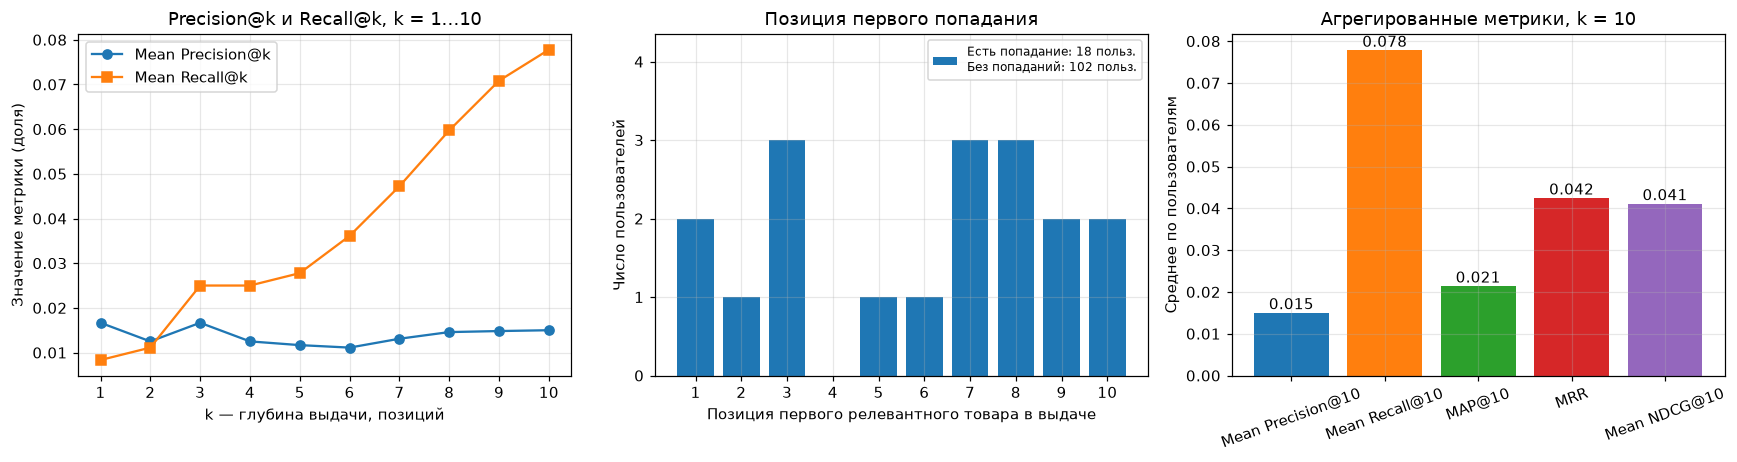

k,1,2,3,4,5,6,7,8,9,10
Mean Precision@k,0.0167,0.0125,0.0167,0.0125,0.0117,0.0111,0.0131,0.0146,0.0148,0.0150
Mean Recall@k,0.0083,0.0111,0.0250,0.0250,0.0278,0.0361,0.0472,0.0597,0.0708,0.0778


In [18]:
ks = range(1, K + 1)
curve = pd.DataFrame({
    "k": list(ks),
    "Mean Precision@k": [np.mean([precision_at_k(r, g, k) for r, g in zip(rec_df["rec"], rec_df["rel"])]) for k in ks],
    "Mean Recall@k": [np.mean([recall_at_k(r, g, k) for r, g in zip(rec_df["rec"], rec_df["rel"])]) for k in ks],
}).set_index("k")
assert np.isclose(curve.loc[K, "Mean Precision@k"], rec_summary[f"Mean Precision@{K}"])
assert np.isclose(curve.loc[K, "Mean Recall@k"], rec_summary[f"Mean Recall@{K}"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
ax = axes[0]
ax.plot(curve.index, curve["Mean Precision@k"], marker="o", label="Mean Precision@k")
ax.plot(curve.index, curve["Mean Recall@k"], marker="s", label="Mean Recall@k")
ax.set_xticks(list(ks)); ax.set_xlabel("k — глубина выдачи, позиций")
ax.set_ylabel("Значение метрики (доля)"); ax.set_title("Precision@k и Recall@k, k = 1…10"); ax.legend()

ax = axes[1]
first_pos = valid["Позиция 1-го попадания"].dropna().astype(int)
counts = first_pos.value_counts().reindex(range(1, K + 1), fill_value=0)
ax.bar(counts.index, counts.values, label=f"Есть попадание: {n_hit_users} польз.\nБез попаданий: {n_users - n_hit_users} польз.")
ax.set_xticks(list(ks)); ax.set_xlabel("Позиция первого релевантного товара в выдаче")
ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
ax.set_ylim(0, max(counts.max(), 1) * 1.45)
ax.set_ylabel("Число пользователей"); ax.set_title("Позиция первого попадания")
ax.legend(fontsize=8)

ax = axes[2]
bars = ax.bar(rec_summary.index, rec_summary.values, color=["C0", "C1", "C2", "C3", "C4"])
ax.bar_label(bars, fmt="%.3f")
ax.set_ylabel("Среднее по пользователям"); ax.set_title(f"Агрегированные метрики, k = {K}")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
curve.round(4).T

In [19]:
# Контекст для интерпретации: (1) случайная выдача из того же каталога; (2) «идеальный» порядок
# тех же самых 10 товаров. Это не новые данные, а точки сравнения для исходной выдачи.
catalog = sorted(set().union(*rec_df["rec"], *rec_df["rel"]))
rng = np.random.default_rng(42)
N_SIM = 500
sims = []
for _ in range(N_SIM):
    um = [user_metrics(list(rng.choice(catalog, size=len(r), replace=False)), g, K)
          for r, g in zip(rec_df["rec"], rec_df["rel"])]
    sims.append(pd.DataFrame(um).mean())
sims = pd.DataFrame(sims)


def oracle_order(rec, rel):
    """Те же объекты, но попадания перенесены в начало списка (порядок внутри групп сохранён)."""
    rel = set(rel)
    return [x for x in rec if x in rel] + [x for x in rec if x not in rel]


oracle = pd.DataFrame([user_metrics(oracle_order(r, g), g, K) for r, g in zip(rec_df["rec"], rec_df["rel"])]).mean()
model_vals = per_user[[f"Precision@{K}", f"Recall@{K}", f"AP@{K}", "RR", f"NDCG@{K}"]].mean()
baseline = pd.DataFrame({
    "Модель (исходный порядок)": model_vals,
    f"Случайная выдача: среднее ({N_SIM} прогонов)": sims.mean(),
    "Случайная: 2,5–97,5 перцентиль": [f"{sims[c].quantile(.025):.4f}–{sims[c].quantile(.975):.4f}" for c in sims],
    "Доля случайных прогонов ≥ модели, %": [100 * (sims[c] >= model_vals[c]).mean() for c in sims],
    "Те же товары, попадания первыми": oracle,
})
print(f"Каталог: {len(catalog)} товаров; ожидаемая Precision@{K} случайной выдачи = "
      f"{np.mean([len(set(g)) for g in rec_df['rel']]) / len(catalog):.4f}")
print("Первое попадание по позициям:", counts[counts > 0].to_dict())
baseline.round(4)

Каталог: 100 товаров; ожидаемая Precision@10 случайной выдачи = 0.0189
Первое попадание по позициям: {1: 2, 2: 1, 3: 3, 5: 1, 6: 1, 7: 3, 8: 3, 9: 2, 10: 2}


,Модель (исходный порядок),Случайная выдача: среднее (500 прогонов),"Случайная: 2,5–97,5 перцентиль","Доля случайных прогонов ≥ модели, %","Те же товары, попадания первыми"
Precision@10,0.0150,0.0187,0.0125–0.0250,86.6,0.0150
Recall@10,0.0778,0.0986,0.0569–0.1417,82.8,0.0778
AP@10,0.0214,0.0293,0.0150–0.0488,80.8,0.0778
RR,0.0424,0.0531,0.0294–0.0832,77.2,0.1500
NDCG@10,0.0411,0.0532,0.0313–0.0781,85.0,0.0933


### 5.3. Интерпретация

**Что показывают метрики (k = 10).**

- **Mean Precision@10 = 0,015** — из 1200 показанных позиций (120 пользователей × 10) релевантны только 18. На витрине из 10 товаров в среднем 0,15 нужного товара.
- **Mean Recall@10 = 0,078** — найдено около 8% известных релевантных товаров.
- **У 102 из 120 пользователей (85%) нет ни одного попадания**, хотя бы один релевантный товар получили 18 пользователей (15%).
- **MAP@10 = 0,021, MRR = 0,042, NDCG@10 = 0,041** — даже найденные товары стоят в среднем низко: первое попадание у 2 пользователей на 1-й позиции, у 10 — на позициях 7–10.
- **Потолок Precision@10.** У пользователей всего 1–3 релевантных товара, поэтому даже идеальная модель получила бы Precision@10 не выше 0,189. Сравнивать Precision@10 нужно с этим потолком, а не с единицей.

**Сравнение со случайной выдачей.** Каталог — 100 товаров; случайные 10 товаров дают в среднем Precision@10 ≈ 0,019 и Recall@10 ≈ 0,099. Все пять метрик модели попадают в 95%-й интервал случайной выдачи, и в 77–87% случайных прогонов результат не хуже модельного. **По этим данным модель неотличима от случайного выбора товаров.**

**Почему важен порядок выдачи.** Precision@10 и Recall@10 не зависят от порядка внутри top-10 — они видят только *набор* товаров. MAP, MRR и NDCG учитывают позицию: если в тех же самых списках поставить попадания первыми, MRR вырастет с 0,042 до 0,150, MAP@10 — с 0,021 до 0,078, NDCG@10 — с 0,041 до 0,093, а Precision@10 и Recall@10 не изменятся. Пример ручного расчёта (пользователь 2) показывает то же самое: попадание на 7-й позиции даёт AP@10 = 0,071 и RR = 0,143, а на 1-й позиции было бы 0,5 и 1,0. Пользователь просматривает выдачу сверху вниз и часто не доходит до 7-й позиции.

### Продуктовый вывод — рекомендации

1. **Результат.** 85% покупателей не видят в подборке ни одного нужного товара, а качество не отличается от случайного набора. Блок рекомендаций в таком виде занимает место на витрине и не помогает продажам.
2. **Основная метрика — NDCG@10**, потому что пользователь видит выдачу сверху вниз и ценность зависит от позиции товара. Precision@10 оцениваем с учётом потолка 0,189.
3. **Ограничение** — доля пользователей без единого попадания (сейчас 85%) должна снижаться; метрики должны быть статистически выше случайной выдачи и простого бейзлайна «популярные товары».
4. **Следующий шаг.** Сначала проверить данные и сопоставление ID товаров между выдачей и релевантными (результат на уровне случайного часто означает ошибку соединения данных). Затем улучшить *генерацию кандидатов* (Recall@10 — совместные покупки, популярное в категории, история пользователя), и только после этого — переранжирование, которое поднимет MAP/MRR/NDCG. Онлайн проверить через A/B-тест по CTR и конверсии в покупку.
5. **Границы вывода.** Модель **требует доработки** и к запуску не готова. Даже после роста офлайн-метрик **данных для решения о запуске недостаточно** без A/B-теста.

## 6. Общий итог по трём кейсам

In [20]:
summary = pd.DataFrame([
    {"Кейс": f"Классификация, в.{VARIANTS['classification']}: {CASE_NAMES[VARIANTS['classification']]}",
     "Ключевые результаты": (f"Precision {cls_metrics['Precision']:.3f}, Recall {cls_metrics['Recall']:.3f}, "
                             f"ROC AUC {cls_metrics['ROC AUC']:.3f}, AP {cls_metrics['AP (average_precision_score)']:.3f}"),
     "Основная метрика": "Precision класса «спам» (доля верных блокировок)",
     "Ограничение": "Recall ≥ согласованного минимума; FPR — по требованию поддержки",
     "Следующий шаг": "Подобрать порог на отложенной выборке; режим «карантин + ручная проверка»"},
    {"Кейс": f"Регрессия, в.{VARIANTS['regression']}: {CASE_NAMES[VARIANTS['regression']]}",
     "Ключевые результаты": (f"MAE {reg_metrics['MAE']:.2f}, RMSE {reg_metrics['RMSE']:.2f}, "
                             f"R² {reg_metrics['R²']:.3f}, MAPE {reg_metrics['MAPE, %']:.1f}%"),
     "Основная метрика": "MAE (ошибка LTV в единицах денег на пользователя)",
     "Ограничение": "Нет систематического смещения по сегментам; MAPE — только справочно",
     "Следующий шаг": "Калибровать края прогноза, убрать обрезку в 0, проверить на новой когорте"},
    {"Кейс": f"Рекомендации, в.{VARIANTS['recsys']}: {CASE_NAMES[VARIANTS['recsys']]}",
     "Ключевые результаты": (f"P@10 {rec_summary['Mean Precision@10']:.3f}, R@10 {rec_summary['Mean Recall@10']:.3f}, "
                             f"MAP@10 {rec_summary['MAP@10']:.3f}, MRR {rec_summary['MRR']:.3f}, "
                             f"NDCG@10 {rec_summary['Mean NDCG@10']:.3f}"),
     "Основная метрика": "NDCG@10 (порядок выдачи на витрине)",
     "Ограничение": f"Доля пользователей без попаданий (сейчас {100 * (1 - n_hit_users / n_users):.0f}%) должна снижаться",
     "Следующий шаг": "Сравнить с бейзлайном «популярное», A/B-тест по CTR и конверсии"},
]).set_index("Кейс")
summary

,Ключевые результаты,Основная метрика,Ограничение,Следующий шаг
Кейс,,,,
"Классификация, в.3: Спам в чате службы поддержки","Precision 0.660, Recall 0.777, ROC AUC 0.855, ...",Precision класса «спам» (доля верных блокировок),Recall ≥ согласованного минимума; FPR — по тре...,Подобрать порог на отложенной выборке; режим «...
"Регрессия, в.8: LTV (жизненная ценность) пользователя","MAE 20.07, RMSE 25.41, R² 0.888, MAPE 26.4%",MAE (ошибка LTV в единицах денег на пользователя),Нет систематического смещения по сегментам; MA...,"Калибровать края прогноза, убрать обрезку в 0,..."
"Рекомендации, в.9: Рекомендации товаров в интернет-магазине","P@10 0.015, R@10 0.078, MAP@10 0.021, MRR 0.04...",NDCG@10 (порядок выдачи на витрине),Доля пользователей без попаданий (сейчас 85%) ...,"Сравнить с бейзлайном «популярное», A/B-тест п..."


| Кейс | Основная метрика | Ограничение | Вердикт |
|---|---|---|---|
| Спам (в. 3) | Precision класса «спам» / FPR | Recall не ниже согласованного минимума | Ранжирует хорошо (ROC AUC 0,855), для автоблокировки порог 0,5 не годится — пригодна с оговорками как сортировка с ручной проверкой |
| LTV (в. 8) | MAE, ед. данных | Нет систематического смещения в сегментах; нет нулевых прогнозов у платящих | R² 0,888, но края прогноза растянуты — пригодна с оговорками после калибровки |
| Товары (в. 9) | NDCG@10 | Доля пользователей без попаданий снижается; модель лучше случайной | На уровне случайной выдачи — требует доработки |

Во всех трёх кейсах требования бизнеса к допустимой ошибке не заданы, поэтому формальное решение звучит одинаково: **данных для решения о запуске недостаточно**.

Общий урок: одна сводная цифра не отвечает на вопрос о запуске. Accuracy скрывает цену FP и FN, нулевое среднее смещение скрывает перекосы по сегментам, а Precision@10 без потолка и бейзлайна легко переоценить или недооценить.

## 6.1. Применение к Sansara

**Ключевая функция Sansara — Matching Engine**: закупщик получает не «похожую позицию», а технически подходящее предложение из остатков другой компании с понятной стоимостью. В нём есть все три типа задач из семинара.

| Задача семинара | Аналог в Sansara | Что переносим |
|---|---|---|
| Классификация и порог | Этап A — «подходит / не подходит» по обязательным характеристикам; пороги Match Score (≥ 90% — автопоказ, 75–89% — подтверждение оператором) | FP = показ несовместимого предложения (кабель 3×2,5 вместо 5×6), FN = упущенный остаток. Пороги Match Score нужно подбирать по размеченным данным, как в разделе 3.4, а не задавать заранее |
| Регрессия | Оценка экономии с учётом доставки, срок поставки | MAE в ₽ и в днях плюс контроль смещения: переоценка экономии разрушает доверие закупщика |
| Рекомендации | Этап B — ранжирование допустимых офферов в ленте | Precision@10, NDCG@10, MRR, доля заявок без подходящего оффера; обязательное сравнение с бейзлайном (сортировка по цене) |

**Техническая метрика Sansara: Precision@10** — доля подходящих предложений среди первых 10 офферов по заявке (по разметке оператора). Дополнительно: Recall@10, NDCG@10. Продуктовые метрики онлайн: Acceptance Rate, Match→Deal Conversion. **North Star Metric не меняется — GMV завершённых сделок**; техническая метрика её не заменяет.

Урок варианта 9 для Sansara: если у заявки всего 1–2 подходящих остатка, Precision@10 ограничена сверху 0,1–0,2 даже у идеального алгоритма. Поэтому Precision@10 считаем только по заявкам, где есть хотя бы один подходящий оффер, и показываем рядом с потолком и NDCG@10.

**Двухэтапный подход.** Ранжирование (этап B) работает только среди предложений, прошедших жёсткую проверку обязательных характеристик (этап A). Метрики ранжирования усредняют качество и не гарантируют безопасность каждой позиции: высокий NDCG@10 совместим с одним несовместимым кабелем в выдаче. Поэтому отдельное ограничение — **0 нарушений обязательных характеристик в показанных офферах**.

**Важно:** метрики учебных моделей не доказывают качество алгоритма Sansara. Собственная модель и размеченные пары «заявка — остаток» ещё не созданы, значения метрик Sansara **не рассчитаны**. Полный план — в [`docs/07_analytics/ml_metrics.md`](../docs/07_analytics/ml_metrics.md).

## 7. Команда, распределение работы и взаимная проверка

Схема слайда 4 (основной раздел + проверка раздела коллеги) адаптирована для команды из 4 человек. Распределение ответственности предложено координатором; команда подтверждает его перед сдачей.

| Участник | Основной раздел | Проверяет | Вклад |
|---|---|---|---:|
| Лебединцев Кирилл Иванович | Сборка ноутбука, общий итог, раздел Sansara, сдача | Все выводы на соответствие расчётам | 25% |
| Щипунов Дмитрий Владимирович | Классификация (в. 3) | Регрессию | 25% |
| Мустафин Денис Димьянович | Регрессия (в. 8, LTV) | Рекомендации | 25% |
| Карпов Максим Сергеевич | Рекомендации (в. 9) и метрики Matching Engine | Классификацию | 25% |

**Чек-лист взаимной проверки (слайд 16)**

- [x] Знаменатели: Precision@k делится на k, AP@k — на min(|rel|, k); положительный класс = 1 (спам); единицы LTV — «ед. данных»; k = 10.
- [x] Число сверено с исходными строками: TP/TN/FP/FN посчитаны вручную и через `confusion_matrix`; порог 0,5 воспроизводит исходный `y_pred`; ручной пример пользователя 2 совпадает с функциями.
- [x] Подписи графиков, осей и легенды на русском; значения на графиках берутся из тех же переменных, что и таблицы.
- [x] Ноутбук перезапущен целиком в чистом окружении (Restart & Run All) без ошибок.

In [21]:
# Приложение А. Все варианты архива одной и той же методикой —
# чтобы при уточнении варианта результаты были доступны без правок кода.
def eval_variant(v):
    task = TASK_OF_VARIANT[v]
    path = DATA_DIR / f"variant_{v}_{task}.csv"
    if task == "classification":
        d = pd.read_csv(path)
        m, _ = classification_metrics(d.y_true, d.y_pred, d.y_score)
        return {"Доля класса 1": d.y_true.mean(), **m}
    if task == "regression":
        d = pd.read_csv(path)
        m = regression_metrics(d.y_true.to_numpy(float), d.y_pred.to_numpy(float))
        return {k: m[k] for k in ["MAE", "RMSE", "R²", "MAPE, %"]}
    d = pd.read_csv(path, dtype=str)
    pairs = list(zip(d.recommended_items.apply(parse_items), d.relevant_items.apply(parse_items)))
    um = pd.DataFrame([user_metrics(r, g, K) for r, g in pairs]).dropna()
    return {"Длина выдачи": max(len(r) for r, _ in pairs), **um.mean().rename(
        {f"Precision@{K}": f"Mean Precision@{K}", f"Recall@{K}": f"Mean Recall@{K}",
         f"AP@{K}": f"MAP@{K}", "RR": "MRR", f"NDCG@{K}": f"Mean NDCG@{K}"}).to_dict()}


for task, vs in [("classification", range(1, 6)), ("regression", range(6, 9)), ("recsys", range(9, 11))]:
    tbl = pd.DataFrame({f"{v}. {CASE_NAMES[v]}": eval_variant(v) for v in vs}).T
    tbl.index.name = f"{task} (наш вариант: {VARIANTS[task]})"
    display(tbl.round(3))

,Доля класса 1,Accuracy,Precision,Recall,F1,ROC AUC,AP (average_precision_score),LogLoss
classification (наш вариант: 3),,,,,,,,
1. Отток клиентов подписочного сервиса,0.230,0.770,0.500,0.772,0.607,0.846,0.712,0.484
2. Мошенничество (фрод) в платежах,0.048,0.820,0.207,0.966,0.341,0.949,0.569,0.468
3. Спам в чате службы поддержки,0.371,0.769,0.660,0.777,0.714,0.855,0.787,0.478
4. Клик по рекламному баннеру (CTR),0.122,0.788,0.333,0.738,0.459,0.860,0.589,0.499
5. Одобрение кредитной заявки,0.376,0.820,0.739,0.805,0.771,0.891,0.845,0.586


,MAE,RMSE,R²,"MAPE, %"
regression (наш вариант: 8),,,,
6. Время доставки заказа,4.517,5.631,0.876,33.151
7. Месячная выручка филиала,71.236,88.813,0.928,26.474
8. LTV (жизненная ценность) пользователя,20.069,25.411,0.888,26.377


,Длина выдачи,Mean Precision@10,Mean Recall@10,MAP@10,MRR,Mean NDCG@10
recsys (наш вариант: 9),,,,,,
9. Рекомендации товаров в интернет-магазине,10.0,0.015,0.078,0.021,0.042,0.041
10. Рекомендации плейлистов в музыкальном сервисе,5.0,0.012,0.056,0.033,0.066,0.047


In [22]:
# Сверка: числа, процитированные в текстовых выводах, совпадают с расчётом.
# Текст написан для вариантов 3 / 8 / 9; при другом наборе вариантов сверка пропускается.
if VARIANTS == {"classification": 3, "regression": 8, "recsys": 9}:
    quoted = [
        ("Precision (спам)", cls_metrics["Precision"], 0.660, 3), ("Recall (спам)", cls_metrics["Recall"], 0.777, 3),
        ("ROC AUC", cls_metrics["ROC AUC"], 0.855, 3), ("AP", cls_metrics["AP (average_precision_score)"], 0.787, 3),
        ("LogLoss", cls_metrics["LogLoss"], 0.478, 3),
        ("FP при 0,3 / 0,5 / 0,8", tuple(thr_table["FP"]), (109, 52, 6), None),
        ("FN при 0,3 / 0,5 / 0,8", tuple(thr_table["FN"]), (10, 29, 89), None),
        ("MAE", reg_metrics["MAE"], 20.07, 2), ("RMSE", reg_metrics["RMSE"], 25.41, 2),
        ("R²", reg_metrics["R²"], 0.888, 3), ("MAPE, %", reg_metrics["MAPE, %"], 26.4, 1),
        ("Нулевых прогнозов LTV", int((yp_r == 0).sum()), 9, None),
        ("Mean Precision@10", rec_summary["Mean Precision@10"], 0.015, 3),
        ("Mean Recall@10", rec_summary["Mean Recall@10"], 0.078, 3), ("MAP@10", rec_summary["MAP@10"], 0.021, 3),
        ("MRR", rec_summary["MRR"], 0.042, 3), ("Mean NDCG@10", rec_summary["Mean NDCG@10"], 0.041, 3),
        ("Пользователей с попаданием", n_hit_users, 18, None),
        ("MRR при идеальном порядке", baseline.loc["RR", "Те же товары, попадания первыми"], 0.150, 3),
    ]
    for name, got, exp, nd in quoted:
        val = got if nd is None else round(float(got), nd)
        assert val == exp, f"{name}: в тексте {exp}, в расчёте {val}"
    print(f"✓ {len(quoted)} чисел из текстовых выводов совпадают с расчётом.")
else:
    print("Варианты изменены: текстовые выводы относятся к вариантам 3/8/9 и требуют обновления.")

✓ 19 чисел из текстовых выводов совпадают с расчётом.


## 8. Воспроизводимость

- Зависимости: `notebooks/requirements.txt` (`pip install -r notebooks/requirements.txt`).
- Запуск: из любой папки внутри репозитория `sansara`. Путь к данным ищется относительно текущей папки, абсолютных путей нет.
- Данные: `data/raw/seminar_10/*.csv`, их целостность проверяется по `SHA256SUMS` в разделе 1.
- Случайность есть только в бейзлайне «случайная выдача» (раздел 5), там зафиксировано `seed = 42`.
- Версии библиотек, на которых выполнен сохранённый прогон:

In [23]:
versions = {"Python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
            "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}
print("Платформа:", platform.platform())
pd.Series(versions, name="Версия").to_frame()

Платформа: Linux-6.18.44-fc-v153-x86_64-with-glibc2.39


,Версия
Python,3.13.17
pandas,3.1.0
numpy,2.5.4
scikit-learn,1.9.1
matplotlib,3.11.2


## Итоговые выводы и дальнейшие действия

1. **Классификация (спам).** Модель хорошо ранжирует (ROC AUC 0,855), но порог 0,5 скрывает 23,6% нормальных обращений. Нужны двухпороговая схема с карантином и подбор порогов на независимых данных.
2. **Регрессия (LTV).** R² 0,888 и MAE 20,1 ед., но низкий LTV систематически недооценивается, высокий — переоценивается, а 9 платящих пользователей получили прогноз 0. Нужна калибровка и проверка на новой когорте.
3. **Рекомендации (товары).** 85% пользователей без попаданий, метрики на уровне случайной выдачи. Сначала проверить данные и генерацию кандидатов, затем ранжирование.
4. **Sansara.** Техническая метрика Matching Engine — Precision@10 (с NDCG@10 и Recall@10) при жёстком ограничении «0 несовместимых предложений». Она служит North Star Metric «GMV завершённых сделок», но не заменяет её. Ближайшее действие — разметить 50–100 пилотных пар «заявка — остаток» и посчитать на них эти метрики.
5. **Открытый вопрос к преподавателю** — подтвердить соответствие кода команды 403 строке 3 таблицы вариантов.